In [1]:
!pip install --quiet PyComplexHeatmap

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as pl
import seaborn as sns
import sys
import yaml
from pathlib import Path
from tqdm.auto import tqdm
from joblib import Parallel, delayed
from scipy.spatial.distance import hamming

# make figures paper quality
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
# matplotlib.rcParams['font.family'] = 'Arial'

import warnings
warnings.filterwarnings("ignore")

In [3]:
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)

seq_primer = config['primer_seq']  # sequence left of gRNA
guide_length = config['guide_length']
# primer will appear between min and max position
pmin, pmax = config['primer_range']['min'], config['primer_range']['max']

path = Path(config['TEMPDIR']) / 'pooled_screen_1/fastq'

In [4]:
cell_line_dict={
    '01': 'H1975',
    '02': 'H1299',
    '03': 'A549'
}

# MAGeCK

In [36]:
# The sgRNA ranking results.
guide_ranking = pd.read_csv('../results/mageck/pooled_screen_1_mageck.sgrna_summary.txt', sep='\t', index_col=0)

In [38]:
guide_ranking.head()

,Gene,control_count,treatment_count,control_mean,treat_mean,LFC,control_var,adj_var,score,p.low,p.high,p.twosided,FDR,high_in_treatment
sgrna,,,,,,,,,,,,,,
HNRNPA1_ENST00000330752_1264,HNRNPA1,100.67/117.18/55.989/67.096/79.897/45.205/742....,1920.8,100.67,1920.8,4.2404,172250.0,62197.0,7.2982,1.0,2.220400e-13,4.440800e-13,2.764400e-09,True
EEF1A1_ENST00000316292_2562,EEF1A1,204.16/63.238/112.61/117.42/59.923/87.898/682....,1545.7,117.42,1545.7,3.7072,98968.0,72542.0,5.3030,1.0,8.517900e-08,1.703600e-07,5.302400e-04,True
HIST1H2BN_ENST00000606613_239,HIST1H2BN,173.79/155/178.66/207.28/166.04/178.31/1138.7/...,1882.4,178.66,1882.4,3.3900,281540.0,110380.0,5.1281,1.0,2.076900e-07,4.153800e-07,8.619000e-04,True
RAN_ENST00000535090_322,RAN,382.45/157.48/149.72/117.42/107.36/151.94/1648...,1725.2,157.48,1725.2,3.4453,736550.0,97290.0,5.0262,1.0,3.607800e-07,7.215700e-07,9.677200e-04,True
ACTG1_ENST00000573283_1731,ACTG1,610.79/348.43/262.33/295.94/248.43/261.18/1415...,2664.0,348.43,2664.0,2.9310,422260.0,215260.0,4.9908,1.0,3.886400e-07,7.772900e-07,9.677200e-04,True


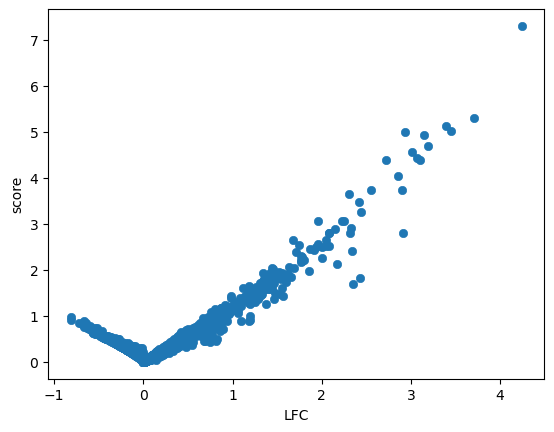

In [37]:
sns.scatterplot(data=tab, x='LFC', y='score', edgecolor=None)
pl.show()

In [40]:
# The gene ranking results.
gene_ranking = pd.read_csv('../results/mageck/pooled_screen_1_mageck.gene_summary.txt', sep='\t', index_col=0)

In [41]:
gene_ranking.head()

,num,"Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|score","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|p-value","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|fdr","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|rank","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|goodsgrna","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|lfc","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|score","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|p-value","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|fdr",...,"sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|fdr","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|rank","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|goodsgrna","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|lfc","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|score","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|p-value","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|fdr","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|rank","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|goodsgrna","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|lfc"
id,,,,,,,,,,,,,,,,,,,,,
ATP5F1D,14,4.795600e-07,0.000025,0.018116,1,6,-0.214260,0.63861,0.68762,1.0,...,0.000009,228,2,-0.027214,0.86390,0.94009,1.0,591,0,-0.027214
PCBP4,21,1.205300e-05,0.000834,0.153080,2,7,-0.233070,0.99986,1.00000,1.0,...,0.579716,718,0,-0.004687,0.45906,0.72722,1.0,321,0,-0.004687
COX8A,7,2.281700e-05,0.000271,0.068841,3,2,-0.101640,0.82811,0.92557,1.0,...,0.000009,316,1,-0.109830,0.35616,0.51852,1.0,253,0,-0.109830
NAA10,14,8.351800e-05,0.002907,0.351147,4,5,-0.155820,0.68690,0.68763,1.0,...,0.000009,278,2,-0.150320,0.67994,0.83514,1.0,475,0,-0.150320
ASB17,7,8.411100e-05,0.000281,0.068841,5,2,-0.019419,0.74969,0.89024,1.0,...,0.579716,594,0,0.055685,0.13486,0.24757,1.0,91,0,0.055685


In [49]:
df = gene_ranking.reset_index().set_index(['id', 'num'])

In [73]:
df.columns = pd.MultiIndex.from_arrays([
    [x.split('_vs_')[0] for x in df.columns],
    [x.split('|')[1] for x in df.columns],
    [x.split('|')[2] for x in df.columns]
])

<Axes: ylabel='id-num'>

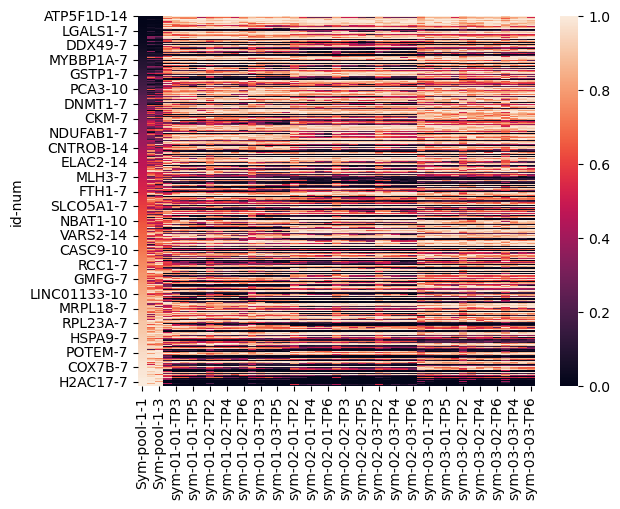

In [82]:
sns.heatmap(df.T.loc[:, 'neg', 'score'].T)

In [79]:
df.T.head(10)

id                               ATP5F1D       PCBP4       COX8A       NAA10  \
num                                   14          21          7           14   
Sym-pool-1-1 neg score      4.795600e-07    0.000012    0.000023    0.000084   
                 p-value    2.468100e-05    0.000834    0.000271    0.002907   
                 fdr        1.811600e-02    0.153080    0.068841    0.351147   
                 rank       1.000000e+00    2.000000    3.000000    4.000000   
                 goodsgrna  6.000000e+00    7.000000    2.000000    5.000000   
                 lfc       -2.142600e-01   -0.233070   -0.101640   -0.155820   
             pos score      6.386100e-01    0.999860    0.828110    0.686900   
                 p-value    6.876200e-01    1.000000    0.925570    0.687630   
                 fdr        1.000000e+00    1.000000    1.000000    1.000000   
                 rank       3.330000e+02  730.000000  500.000000  365.000000   

id                               ASB17       LSM11       PCAT1      CHCHD7  \
num                                 7           7           20          21   
Sym-pool-1-1 neg score        0.000084    0.000248    0.000759    0.000844   
                 p-value      0.000281    0.002611    0.008258    0.009522   
                 fdr          0.068841    0.351147    0.351147    0.351147   
                 rank         5.000000    6.000000    7.000000    8.000000   
                 goodsgrna    2.000000    2.000000    3.000000    4.000000   
                 lfc         -0.019419   -0.126870   -0.154400   -0.060956   
             pos score        0.749690    0.613010    0.986660    0.976530   
                 p-value      0.890240    0.790640    0.998670    0.995910   
                 fdr          1.000000    1.000000    1.000000    1.000000   
                 rank       424.000000  303.000000  692.000000  672.000000   

id                                ELOB   FOXC2-AS1  ...     HNRNPA1  \
num                                 14          10  ...          7    
Sym-pool-1-1 neg score        0.001245    0.001464  ...    0.998860   
                 p-value      0.010193    0.016670  ...    0.986820   
                 fdr          0.351147    0.351147  ...    1.000000   
                 rank         9.000000   10.000000  ...  724.000000   
                 goodsgrna    4.000000    3.000000  ...    0.000000   
                 lfc         -0.139490   -0.232310  ...    1.025500   
             pos score        0.965490    0.996340  ...    0.000006   
                 p-value      0.993310    0.999810  ...    0.000005   
                 fdr          1.000000    1.000000  ...    0.000025   
                 rank       651.000000  715.000000  ...    4.000000   

id                              NUP133      H2AC17        EIF4A1      NFE2L2  \
num                                 7           7             7           7    
Sym-pool-1-1 neg score        0.999270    0.999580  9.997000e-01    0.999720   
                 p-value      0.989870    0.995080  9.963900e-01    0.996390   
                 fdr          1.000000    1.000000  1.000000e+00    1.000000   
                 rank       725.000000  726.000000  7.270000e+02  728.000000   
                 goodsgrna    0.000000    0.000000  0.000000e+00    0.000000   
                 lfc          0.039238    0.202650  1.562600e+00    0.131890   
             pos score        0.224910    0.125880  2.194500e-07    0.280100   
                 p-value      0.000005    0.000005  4.936200e-06    0.000005   
                 fdr          0.000025    0.000025  2.500000e-05    0.000025   
                 rank       117.000000   88.000000  2.000000e+00  135.000000   

id                               RPS14        RPS5      TMSB4X        DDX5  \
num                                 14          7           7           7    
Sym-pool-1-1 neg score        0.999930    0.999940    0.999950    1.000000   
                 p-value      0.996390    0.999190    

In [53]:
df.columns

Index(['Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|score',
       'Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|p-value',
       'Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|fdr',
       'Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|rank',
       'Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|goodsgrna',
       'Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|lfc',
       'Sym-pool-1-1_vs_sym

# Counts

In [5]:
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

In [6]:
df.head()

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,sym-03-02-TP2,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
AATBC_ENST00000400385_1005,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0983:983-1005,ACAGAACCCTAGGAAGCAACCTC,1005.0,0.789626,Gene_Body,4598.0,...,1235,1494,1747,1655,1494,1545,1298,1842,1277,1391
AATBC_ENST00000400385_1562,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1504:1540-1562,CCAGGCCACTTGCTCCACCCTCT,1562.0,0.747814,Gene_Body,4598.0,...,1885,2072,2450,2161,2318,2164,1775,2276,1863,2168
AATBC_ENST00000400385_1938,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1862:1916-1938,TGACCTCTCACCCCGCAGCCTCT,1938.0,0.747682,Gene_Body,4598.0,...,1199,1299,1680,1402,1473,1463,1166,1650,1139,1391
AATBC_ENST00000400385_2713,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA2601:2691-2713,CTGCCTTATAAAGATAGACCGGT,2713.0,0.870540,Gene_Body,4598.0,...,799,1175,1268,1071,1026,1157,892,1263,835,1073
AATBC_ENST00000400385_28,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0006:6-28,CCGGTCTCTGCAGTCACCCTCCT,28.0,0.762563,Gene_Body,4598.0,...,1518,1898,2201,1797,1975,2039,1678,2248,1576,1842


In [7]:
sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1' 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]

## Normalization

In [180]:
# I think median control normalization seems best

In [181]:
# Seq Depth Normalization
n_counts = df[sample_names].sum()
df_depth = df[sample_names] / n_counts * np.median(n_counts)

In [182]:
# Median norm with control guides
median_counts_control = df.loc[controls, sample_names].median()
df_medctrl = df[sample_names] / median_counts_control

<Axes: ylabel='unique_guide_name'>

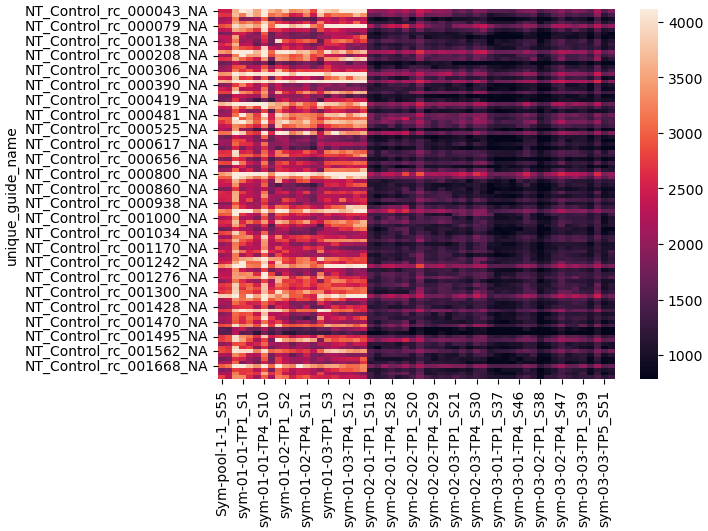

In [183]:
# control raw
sns.heatmap(df.loc[controls, sample_names], robust=True)

<Axes: ylabel='unique_guide_name'>

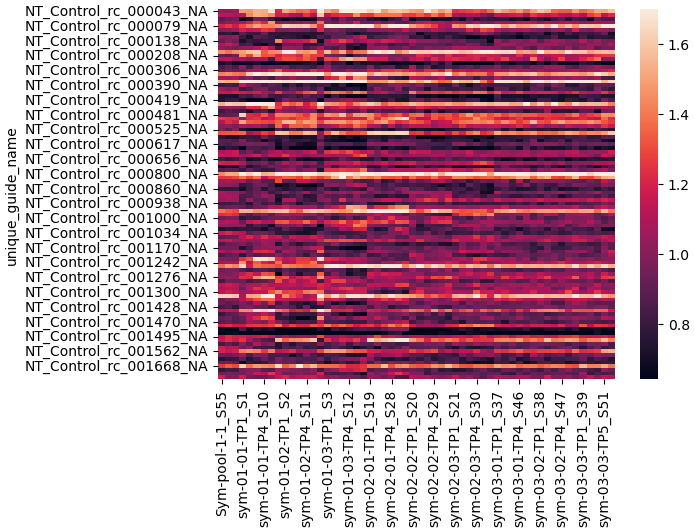

In [184]:
# control after median normalization
sns.heatmap(df_medctrl.loc[controls, sample_names], robust=True)

<Axes: ylabel='unique_guide_name'>

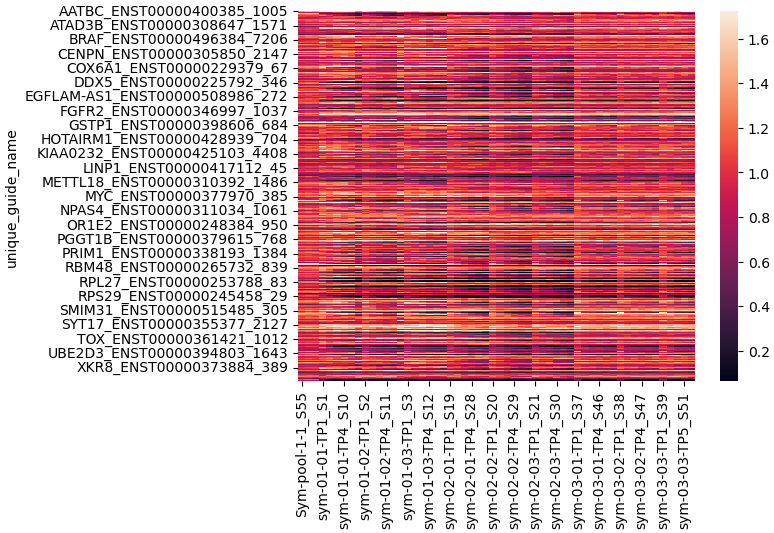

In [185]:
# all after median normalization
sns.heatmap(df_medctrl.loc[:, sample_names], robust=True)

<Axes: ylabel='unique_guide_name'>

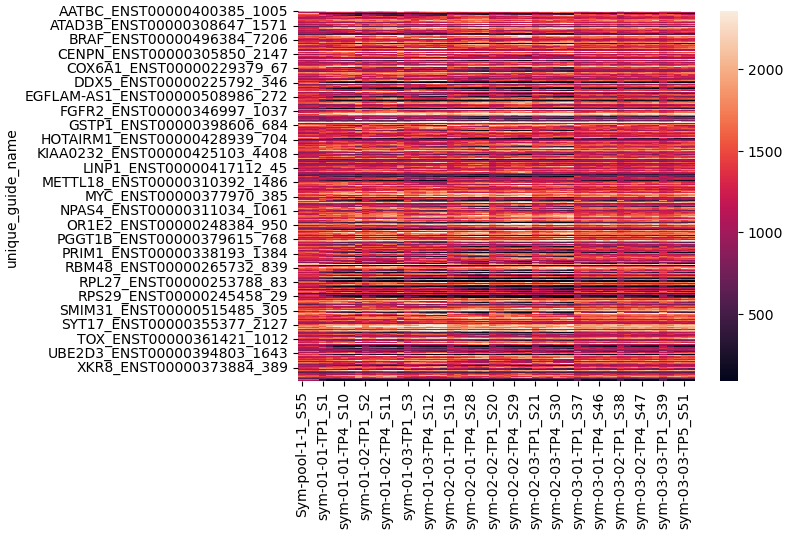

In [186]:
# all after depth normalization
sns.heatmap(df_depth.loc[:, sample_names], robust=True)

## Big heatmap

In [8]:
# Median norm with control guides
median_counts_control = df.loc[controls, sample_names].median()
fc = df[sample_names] / median_counts_control
l2fc = np.log2(fc)

In [12]:
l2fc[l2fc==-np.infty] = None

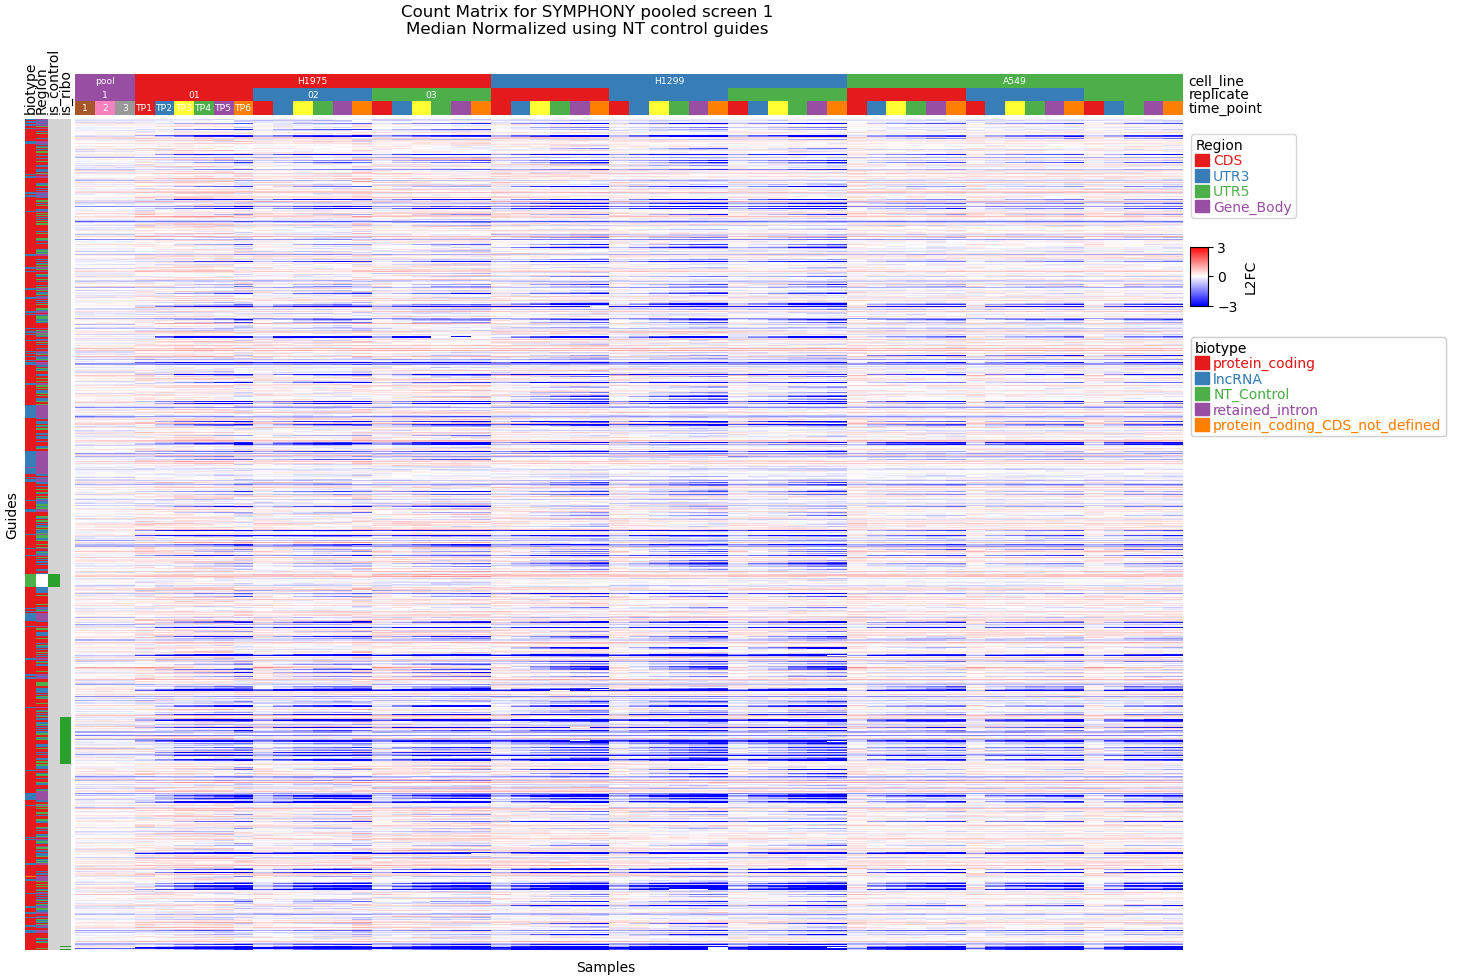

In [16]:
import PyComplexHeatmap as pch
data = l2fc.loc[:, sample_names]

cell_line = pd.Series({x: x.split('-')[1] for x in data.columns}).replace(cell_line_dict)
replicate = pd.Series({x: x.split('-')[2] for x in data.columns})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in data.columns})

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line, add_text=True),
    replicate=pch.anno_simple(replicate, add_text=True),
    time_point=pch.anno_simple(time_point, add_text=True),
    verbose=0, axis=1, plot_legend=False
)

is_control = pd.Series(np.array(['control' in x.lower() for x in df.index], dtype=str), index=df.index)
is_ribo = pd.Series(np.array([(x[:3]=='RPS') or (x[:3]=='RPL') for x in df.index], dtype=str), index=df.index)

left_ha = pch.HeatmapAnnotation(
    biotype=pch.anno_simple(df['transcript_biotype'], legend=True),
    Region=pch.anno_simple(df['Region'], legend=True),
    is_control=pch.anno_simple(is_control, colors={'False': 'lightgrey', 'True': 'tab:green'}, legend=False),
    is_ribo=pch.anno_simple(is_ribo, colors={'False': 'lightgrey', 'True': 'tab:green'}, legend=False),
    verbose=0, axis=0, plot_legend=True
)

pl.figure(figsize=(15, 10))
cm = pch.ClusterMapPlotter(
    data=data, left_annotation=left_ha, top_annotation=top_ha,
    row_cluster=False, col_cluster=False,
    label='beta', row_dendrogram=False, legend_gap=7,
    rasterized=True, cmap='bwr', vmin=-3, vmax=3,
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='Guides', legend_hpad=0,
    verbose=0
)
pl.suptitle('Count Matrix for SYMPHONY pooled screen 1\nMedian Normalized using NT control guides', y=0.95)
pl.savefig('../results/figures/count_matrix_l2fc_heatmap.png', dpi=300)
pl.show()

In [21]:
l2fc.sort_values('sym-01-01-TP6')

,Sym-pool-1-1,Sym-pool-1-2,Sym-pool-1-3,sym-01-01-TP1,sym-01-01-TP2,sym-01-01-TP3,sym-01-01-TP4,sym-01-01-TP5,sym-01-01-TP6,sym-01-02-TP1,...,sym-03-02-TP2,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
SNRPD1_ENST00000579618_81,0.077441,0.166567,0.099777,-0.819037,-2.736877,-4.335904,-5.856850,-6.548236,-10.443980,-1.554343,...,-1.661373,-2.541659,-2.834967,-2.928611,-3.289381,0.067729,-1.524720,-3.299827,-3.655917,-3.838435
FBL_ENST00000597224_522,0.193407,0.278906,0.267713,-0.617285,-2.301699,-5.026800,-8.638210,-7.371358,-10.443980,-0.756224,...,-0.589750,-1.291983,-1.478606,-1.554093,-2.162001,0.399735,-0.771102,-1.905654,-1.752593,-2.041169
PCNA_ENST00000379143_743,0.351794,0.322965,0.408526,-0.764155,-2.365711,-3.100801,-4.211945,-4.823870,-9.859017,-1.400853,...,-2.199587,-2.902331,-3.430422,-3.492137,-4.788186,-0.283817,-2.245284,-3.754393,-4.162877,-4.552131
RPS18_ENST00000439602_236,0.176245,0.226177,0.226070,-1.155929,-2.441291,-5.401196,-7.937770,-5.579944,-9.443980,-2.244696,...,-2.460115,-3.688500,-3.633636,-3.682959,-4.611309,-0.414474,-2.559393,-4.083015,-4.747840,-4.769723
FBL_ENST00000597224_524,0.206146,0.238120,0.244167,-0.346947,-2.722836,-6.632521,NaN,NaN,-9.443980,-1.214350,...,-1.412082,-1.923832,-2.484060,-2.230167,-2.682392,0.219732,-1.208131,-2.788181,-2.918952,-2.986534
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FBL_ENST00000221801_1119,0.161603,0.183314,0.078955,-0.363301,-2.628200,-6.201887,-8.468285,-8.264443,NaN,-1.365628,...,-0.890259,-1.423627,-1.884598,-2.036191,-2.611309,0.076310,-0.711396,-1.950859,-2.395854,-2.744776
RAN_ENST00000392367_279,0.107176,0.175775,0.080165,-2.029449,-3.278408,-4.927264,-4.805320,-6.548236,NaN,-2.962237,...,-3.150259,-3.535026,-4.188604,-4.405425,-4.757159,-0.634864,-2.777891,-3.985718,-4.137786,-4.218707
RPS6_ENST00000315377_447,-0.024904,0.049458,0.072487,-1.092394,-2.978206,-6.632521,-7.245892,-7.901873,NaN,-2.210438,...,-2.723149,-2.666585,-3.773567,-3.773157,-5.063821,-0.588349,-2.468722,-4.151728,-3.995767,-4.838435


Text(0, 0.5, 'L2FC SNRPD1_ENST00000579618_81')

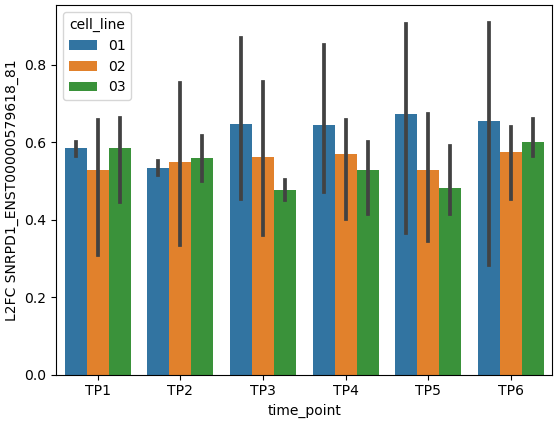

In [41]:
sdf = l2fc.loc[controls[0]].to_frame()
sdf['cell_line'] = [x.split('-')[1] for x in sdf.index]
sdf['replicate'] = [x.split('-')[2] if 'pool' not in x else '0'+x[-1] for x in sdf.index ]
sdf['time_point'] = [x.split('-')[3][:3] if 'pool' not in x else 'Pool' for x in sdf.index ]
sdf = sdf[sdf.cell_line!='pool']
sns.barplot(data=sdf, y=controls[0], x='time_point', hue='cell_line')
pl.ylabel('L2FC SNRPD1_ENST00000579618_81')

Text(0, 0.5, 'L2FC SNRPD1_ENST00000579618_81')

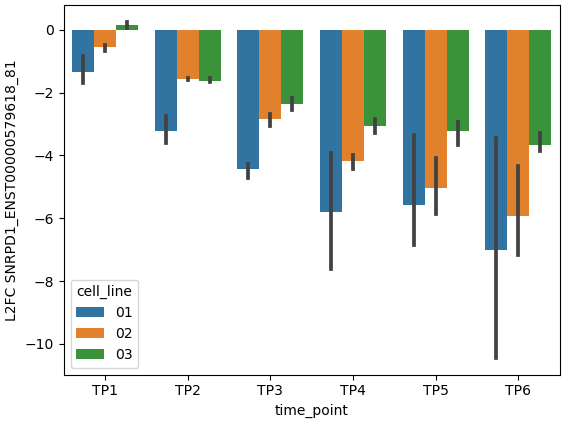

In [38]:
sdf = l2fc.loc['SNRPD1_ENST00000579618_81'].to_frame()
sdf['cell_line'] = [x.split('-')[1] for x in sdf.index]
sdf['replicate'] = [x.split('-')[2] if 'pool' not in x else '0'+x[-1] for x in sdf.index ]
sdf['time_point'] = [x.split('-')[3][:3] if 'pool' not in x else 'Pool' for x in sdf.index ]
sdf = sdf[sdf.cell_line!='pool']
sns.barplot(data=sdf, y='SNRPD1_ENST00000579618_81', x='time_point', hue='cell_line')
pl.ylabel('L2FC SNRPD1_ENST00000579618_81')

In [33]:
sdf

,SNRPD1_ENST00000579618_81,cell_line,replicate,time_point
Sym-pool-1-1,0.077441,pool,01,Pool
Sym-pool-1-2,0.166567,pool,02,Pool
Sym-pool-1-3,0.099777,pool,03,Pool
sym-01-01-TP1,-0.819037,01,01,TP1
sym-01-01-TP2,-2.736877,01,01,TP2
sym-01-01-TP3,-4.335904,01,01,TP3
sym-01-01-TP4,-5.856850,01,01,TP4
sym-01-01-TP5,-6.548236,01,01,TP5
sym-01-01-TP6,-10.443980,01,01,TP6
sym-01-02-TP1,-1.554343,01,02,TP1


# Log Fold Change

In [9]:
# change w.r.t. initial time point
# OR
# change w.r.t. pool?
# OR
# L2FC of guide counts w.r.t. NT controls?

In [12]:
# Option 1
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1' 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]

In [13]:
# Seq Depth Normalization
n_counts = df[sample_names].sum()
df_depth = df[sample_names] / n_counts * np.median(n_counts)

In [31]:
fc = df[sample_names] / np.median(df.loc[controls, sample_names])
l2fc = np.log2(fc)

# Trimming

## Eval trimming

In [102]:
qcs = {x.name.split('_R1_001')[0]: pd.read_csv(x, sep='\t') for x in (Path(config['TEMPDIR']) /'pooled_screen_1/trimmed/qc').glob('*')}
df = pd.concat(qcs).droplevel(1)

In [103]:
df['fraction_filtered'] = df.Filtered_reads / df.Total_reads
df['cell_line'] = [x.split('-')[1] for x in df.index]
df['lane'] = [x.split('_')[-1] for x in df.index]
df['replicate'] = [x.split('-')[2] if 'pool' not in x else '0'+x[-5] for x in df.index ]
df['time_point'] = [x.split('-')[3][:3] if 'pool' not in x else 'Pool' for x in df.index ]

In [104]:
df.head()

,Mean_primer_distance,Mean_primer_certainty,Filtered_reads,Total_reads,fraction_filtered,cell_line,lane,replicate,time_point
sym-03-01-TP2_S40_L001,0.393326,0.186740,146127,3752185,0.038945,03,L001,01,TP2
sym-01-02-TP5_S14_L002,0.391821,0.192538,386904,7378938,0.052434,01,L002,02,TP5
sym-03-02-TP2_S41_L001,0.394498,0.185374,154890,3864224,0.040083,03,L001,02,TP2
sym-02-02-TP6_S35_L001,0.396969,0.182575,138160,3814596,0.036219,02,L001,02,TP6
sym-03-01-TP6_S52_L001,0.396831,0.182833,153899,4265629,0.036079,03,L001,01,TP6


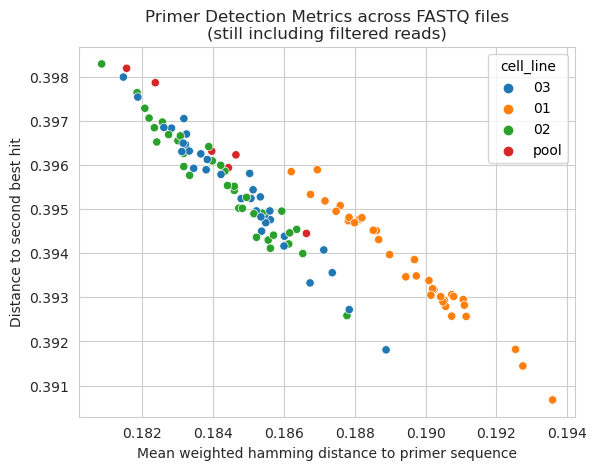

In [106]:
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots()
sns.scatterplot(data=df, y='Mean_primer_distance', hue='cell_line', x='Mean_primer_certainty', ax=ax)
pl.xlabel('Mean weighted hamming distance to primer sequence')
pl.ylabel('Distance to second best hit')
pl.title('Primer Detection Metrics across FASTQ files\n(still including filtered reads)')
pl.savefig('../results/figures/trimming_qc_medians.pdf', bbox_inches='tight')
pl.show()

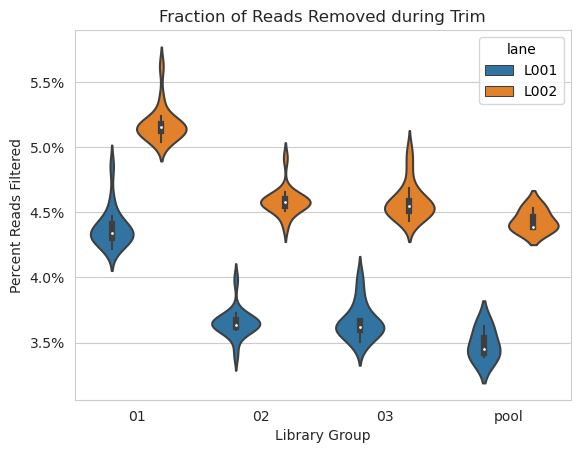

In [107]:
import matplotlib.ticker as mtick
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots()
sns.violinplot(data=df, x='cell_line', hue='lane', y='fraction_filtered', ax=ax, order=['01', '02', '03', 'pool'])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1,1))
pl.ylabel('Percent Reads Filtered')
pl.xlabel('Library Group')
pl.title('Fraction of Reads Removed during Trim')
pl.savefig('../results/figures/trimming_fraction_reads_removed.pdf', bbox_inches='tight')
pl.show()

## Finding cut-offs

In [4]:
def qual_to_float(qual):
    return list(map(ord, qual))
def make_substrings(s, K):
    return [s[i: j] for i in range(len(s)) for j in range(i + 1, len(s) + 1) if len(s[i:j]) == K]

def trim_sequence(read, quality):
    K = len(seq_primer)
    
    # search primer in expected region
    subs = make_substrings(read[pmin:pmax+K], K)
    weights = make_substrings(quality[pmin:pmax+K], K)
    primer_alignment = pd.DataFrame(index=np.arange(len(subs)), columns=['idx', 'sequence', 'hamming_distance'])
    for j, sub, w in zip(range(len(subs)), subs, weights):
        ham = hamming(list(seq_primer), list(sub), qual_to_float(w))
        primer_alignment.iloc[j] = [j+pmin, sub, ham]
    primer_alignment = primer_alignment.sort_values('hamming_distance')
    primer_idx, primer_hit, primer_distance = primer_alignment.iloc[0]
    primer_certainty = primer_alignment.hamming_distance.iloc[1] - primer_alignment.hamming_distance.iloc[0]
    
    # select guide position after primer
    trimmed_seq = read[primer_idx+K : primer_idx+K+guide_length]
    trimmed_qual = quality[primer_idx+K : primer_idx+K+guide_length]
    
    return trimmed_seq, trimmed_qual, primer_idx, primer_hit, primer_distance, primer_certainty

In [5]:
# deep one
file = path / 'sym-01-01-TP1_S1_L001_R1_001.fastq'

In [14]:
def process(line1, line2, line3, line4):
    index = line1
    sequence = line2.replace('\n', '')
    qual = line4.replace('\n', '')

    trimmed_seq, trimmed_qual, primer_idx, primer_hit, primer_distance, primer_certainty = trim_sequence(sequence, qual)
    return index, trimmed_seq, trimmed_qual

def chunker(seq, size):
    return (seq[pos:pos + size] for pos in range(0, len(seq), size))

# Parallel processing
with open(file, 'r') as INPUT:
    lines = INPUT.readlines()[:10000]  # test
    n_reads = int(len(lines) / 4)
    results = Parallel(n_jobs=4)(delayed(process)(line1, line2, line3, line4) for line1, line2, line3, line4 in tqdm(chunker(lines, size=4), total=n_reads))

# write to file
with open(file.with_suffix('.trimmed.fastq') , mode='w') as OUTPUT:
    for index, trimmed_seq, trimmed_qual in tqdm(results, total=n_reads):
        OUTPUT.write(index)
        OUTPUT.write(trimmed_seq+'\n')
        OUTPUT.write('+\n')
        OUTPUT.write(trimmed_qual+'\n')

  0%|          | 0/2500 [00:00<?, ?it/s]

  0%|          | 0/2500 [00:00<?, ?it/s]

In [9]:
# deep one
file = path / 'sym-01-01-TP1_S1_L001_R1_001.fastq'

dat = []
with open(file, 'r') as INPUT, \
     open(file.with_suffix('.trimmed.fastq') , mode='w') as OUTPUT:
    lines = INPUT.readlines()
    n_reads = int(len(lines) / 4)
    for i in tqdm(range(n_reads)):
        index = lines[4*i]
        sequence = lines[4*i+1].replace('\n', '')
        qual = lines[4*i+3].replace('\n', '')
        
        trimmed_seq, trimmed_qual, primer_idx, primer_hit, primer_distance, primer_certainty = trim_sequence(sequence, qual)
        dat.append([primer_distance, primer_certainty])
        OUTPUT.write(index)
        OUTPUT.write(trimmed_seq+'\n')
        OUTPUT.write('+\n')
        OUTPUT.write(trimmed_qual+'\n')
        
        if i>10000:
            break

  0%|          | 0/11277957 [00:00<?, ?it/s]

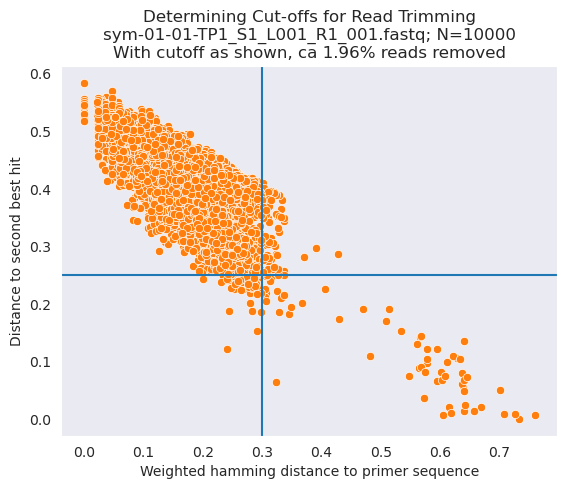

In [10]:
df = pd.DataFrame(dat, columns=['primer_distance', 'primer_certainty'])
with sns.axes_style('dark'):
    sns.scatterplot(data=df, x='primer_distance', y='primer_certainty', c='tab:orange')
xcut = 0.3
ycut = 0.25
removal = np.round(100 - 100 * len(df[(df.primer_distance < 0.3) & (df.primer_certainty > 0.25)]) / len(df), 2)
pl.axvline(xcut)
pl.axhline(ycut)
pl.title(f'Determining Cut-offs for Read Trimming\n{file.name}; N=10000\nWith cutoff as shown, ca {removal}% reads removed')
pl.xlabel('Weighted hamming distance to primer sequence')
pl.ylabel('Distance to second best hit')
pl.show()

In [11]:
# a shallow one
file = path / 'sym-02-01-TP1_S19_L001_R1_001.fastq'

dat = []
with open(file, 'r') as INPUT, \
     open(file.with_suffix('.trimmed.fastq') , mode='w') as OUTPUT:
    lines = INPUT.readlines()
    n_reads = int(len(lines) / 4)
    for i in tqdm(range(n_reads)):
        index = lines[4*i]
        sequence = lines[4*i+1].replace('\n', '')
        # line 3 is just "+"
        qual = lines[4*i+3].replace('\n', '')
        
        trimmed_seq, trimmed_qual, primer_idx, primer_hit, primer_distance, primer_certainty = trim_sequence(sequence, qual)
        dat.append([primer_distance, primer_certainty])
        OUTPUT.write(index)
        OUTPUT.write(trimmed_seq+'\n')
        OUTPUT.write('+\n')
        OUTPUT.write(trimmed_qual+'\n')
        
        if i>10000:
            break

  0%|          | 0/5025827 [00:00<?, ?it/s]

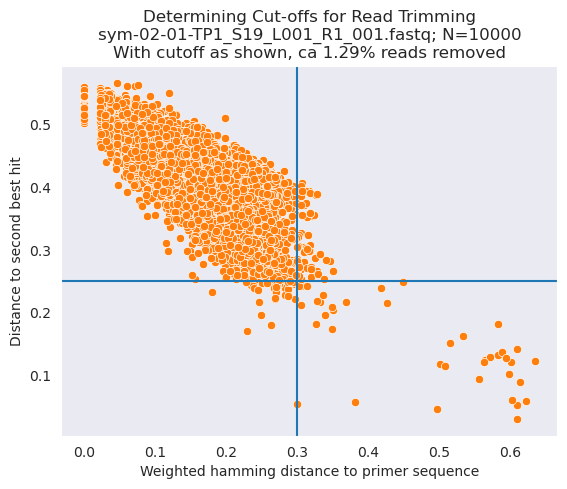

In [12]:
df = pd.DataFrame(dat, columns=['primer_distance', 'primer_certainty'])
with sns.axes_style('dark'):
    sns.scatterplot(data=df, x='primer_distance', y='primer_certainty', c='tab:orange')
xcut = 0.3
ycut = 0.25
removal = np.round(100 - 100 * len(df[(df.primer_distance < 0.3) & (df.primer_certainty > 0.25)]) / len(df), 2)
pl.axvline(xcut)
pl.axhline(ycut)
pl.title(f'Determining Cut-offs for Read Trimming\n{file.name}; N=10000\nWith cutoff as shown, ca {removal}% reads removed')
pl.xlabel('Weighted hamming distance to primer sequence')
pl.ylabel('Distance to second best hit')
pl.show()

# Evaluate guide counting /alignment

In [108]:
alignment_qc = pd.read_csv('../results/multiqc/multiqc_data/mqc_samtools_alignment_plot_1.txt', sep='\t', index_col=0)
alignment_qc['sample_id'] = [x.split('_L00')[0] for x in alignment_qc.index ]
alignment_qc = alignment_qc.groupby('sample_id').mean()  # merge lanes
alignment_qc['cell_line'] = [x.split('-')[1] for x in alignment_qc.index ]
alignment_qc['replicate'] = [x.split('-')[2] if 'pool' not in x else '0'+x[-5] for x in alignment_qc.index ]
alignment_qc['time_point'] = [x.split('-')[3][:3] if 'pool' not in x else 'Pool' for x in alignment_qc.index ]
alignment_qc['total_reads'] = alignment_qc.sum(1)
alignment_qc['fraction_mapped'] = alignment_qc['Mapped (with MQ>0)'] / alignment_qc['total_reads']
alignment_qc['cell_line_x_replicate'] = [f'{x}_{y}' for x, y in zip(alignment_qc.cell_line, alignment_qc.replicate)]

In [109]:
alignment_qc.head()

,Mapped (with MQ>0),MQ0,Unmapped,cell_line,replicate,time_point,total_reads,fraction_mapped,cell_line_x_replicate
sample_id,,,,,,,,,
Sym-pool-1-1_S55,7307104.0,16560.5,840031.0,pool,01,Pool,8163695.5,0.895073,pool_01
Sym-pool-1-2_S56,7537114.0,17022.0,869478.0,pool,02,Pool,8423614.0,0.894760,pool_02
Sym-pool-1-3_S57,10628746.5,23438.0,1195289.5,pool,03,Pool,11847474.0,0.897132,pool_03
sym-01-01-TP1_S1,9467309.0,24452.0,1199177.0,01,01,TP1,10690938.0,0.885545,01_01
sym-01-01-TP2_S4,8729523.5,22547.0,1078519.5,01,01,TP2,9830590.0,0.887996,01_01


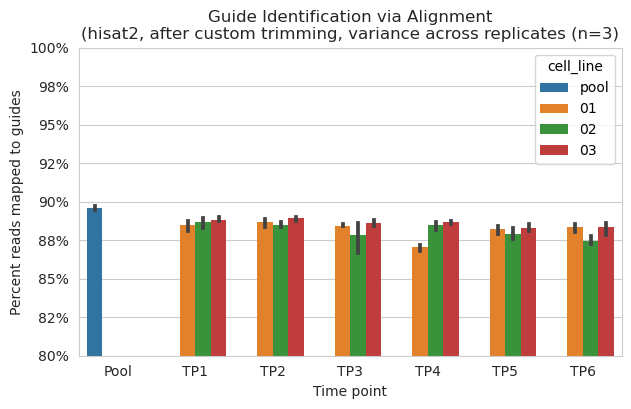

In [110]:
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(figsize=(7,4))
sns.barplot(data=alignment_qc.reset_index(), x='time_point', y='fraction_mapped', ax=ax, hue='cell_line', dodge=True)
import matplotlib.ticker as mtick
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0))
ax.set_ylim([0.8,1])
ax.set_ylabel('Percent reads mapped to guides')
ax.set_xlabel('Time point')
ax.set_title('Guide Identification via Alignment\n(hisat2, after custom trimming, variance across replicates (n=3)')
pl.savefig('../results/figures/guide_alignment_qc_mapping.pdf', bbox_inches='tight')
pl.show()

# Custom guide counting (outdated, now using aligner + samtools)

In [205]:
guide_df = pd.read_csv('../resources/all_gRNA_data.csv', index_col='unique_guide_name')
guide_df.head()

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,gRNA_occurence,transcript_per_gene
unique_guide_name,,,,,,,,,,,,
CYP26B1_ENST00000001146_2702,ENST00000001146,ENSG00000003137,CYP26B1,protein_coding,crRNA2661:2680-2702,TTAAACCCAAATAATGCCCGGAG,2702.0,1.306530,UTR3,4556.0,1,2
CYP26B1_ENST00000001146_4708,ENST00000001146,ENSG00000003137,CYP26B1,protein_coding,crRNA4464:4686-4708,AAGCCTATAGAAGAGCCACATTG,4708.0,1.411459,UTR3,4556.0,1,2
NDUFAB1_ENST00000007516_654,ENST00000007516,ENSG00000004779,NDUFAB1,protein_coding,crRNA632:632-654,AAGTCCATCAGAATCACTCTGTC,654.0,1.012291,UTR3,665.0,1,1
NDUFAB1_ENST00000007516_667,ENST00000007516,ENSG00000004779,NDUFAB1,protein_coding,crRNA645:645-667,ACAATTTAAATACAAGTCCATCA,667.0,0.996597,UTR3,665.0,1,1
RPS20_ENST00000009589_568,ENST00000009589,ENSG00000008988,RPS20,protein_coding,crRNA508:546-568,CTTTATATTCCTAAAATCTGCCA,568.0,0.821865,UTR3,519.0,1,1


## New

In [55]:
# deep one
input_file = Path(config['TEMPDIR']) / 'pooled_screen_1/trimmed/sym-01-01-TP1_S1_L001_R1_001_custom_trimmed.fastq'

In [78]:
def identify_guide(sequence, quality, quality_cutoff=60):    
    qual = qual_to_float(quality)
    lowest_q = np.min(qual)
    
    high_quality = lowest_q > quality_cutoff
    direct_hit = sequence in guide_df.GuideSeq

    # Find guide
    if high_quality and direct_hit:
        # search for direct hit
        row = guide_df[guide_df.GuideSeq==sequence].iloc[0]
        guide_id = row.index
        guide_hit = row.GuideSeq
        guide_score = 1
        guide_certainty = 1
        next_best_guide = 'None'
    else:
        if not high_quality:
            print(sequence, ' Not trusting the quality!, quality >=', lowest_q)
        else:
            print(sequence, ' High quality, but no direct hit!, quality >=', lowest_q)
        # search best-fitting guide
        guide_alignment = pd.DataFrame(index=np.arange(len(guide_df)), columns=['guide_id', 'guide_sequence', 'score'])
        for j, index, guide in zip(range(len(guide_df)), guide_df.index, guide_df.GuideSeq):
            ham = hamming(list(sequence), list(guide), qual)
            guide_alignment.iloc[j] = [index, guide, 1 - ham]
        guide_alignment = guide_alignment.sort_values('score')
        guide_id, guide_hit, guide_score = guide_alignment.iloc[0]
        guide_certainty = guide_alignment.score.iloc[1] - guide_alignment.score.iloc[0]
        next_best_guide = guide_alignment.guide_id.iloc[1]
    
    return [guide_id, guide_hit, guide_score, guide_certainty, next_best_guide]

def chunker(seq, size):
    return (seq[pos:pos + size] for pos in range(0, len(seq), size))

In [56]:
with open(input_file, 'r') as INPUT:
    lines = INPUT.readlines()
    n_reads = int(len(lines) / 4)

In [79]:
iterator = chunker(lines, 4)
i = 0
res = []
for line1, line2, line3, line4 in iterator:
    index = line1
    sequence = line2.replace('\n', '')
    qual = line4.replace('\n', '')
    
    re = identify_guide(sequence, qual)
    res.append(re)
    
    i+=1
    if i>30:
        break

GCCTGTACTTTGGGGTGACTGCA  Not trusting the quality!, quality >= 58
AGACATTACTAATTTTGCCAGTC  High quality, but no direct hit!, quality >= 70
AAGCCAAGATCAACACACACTGG  High quality, but no direct hit!, quality >= 70
GAGGCACTATCAGATTAGCCCTA  Not trusting the quality!, quality >= 58
CCAACAGATCAGAGGACCCCATA  High quality, but no direct hit!, quality >= 70
GTGAAAGTACTACTACAGACACG  High quality, but no direct hit!, quality >= 70
TTGCACGTCAAATCTGGGGCTGA  High quality, but no direct hit!, quality >= 70
TGCACAAATCAGTGCCTGTCCCA  High quality, but no direct hit!, quality >= 70
TCCTCAATTTCTCCAAAGCCCGT  High quality, but no direct hit!, quality >= 70
ATCCAAGTGTAGATCTGCAACTC  High quality, but no direct hit!, quality >= 70
TCTCGGACACTTAGACCCACTGA  High quality, but no direct hit!, quality >= 70
TAGCAGCAAAACTTCCGGGAACA  Not trusting the quality!, quality >= 58
CCTTGAAGTAATAGACACCAGTC  Not trusting the quality!, quality >= 58
ATGAGATCAACCTTTTCCACCAG  High quality, but no direct hit!, quality >= 70
CCTTCT

In [88]:
tab = pd.DataFrame(res, columns='guide_id, guide_hit, guide_score, guide_certainty, next_best_guide'.split(', '))

In [109]:
tab.head()

,guide_id,guide_hit,guide_score,guide_certainty,next_best_guide
0,LNCARSR_ENST00000413352_1399,AATGTCTTCCATAAAGTGGCCAT,0.000000,0.000000,RPS17_ENST00000559187_346
1,SAMM50_ENST00000350028_1614,GCCTTGCTGCTGCCCCAGTCCCA,0.000000,0.000000,HOTTIP_ENST00000521028_546
2,RPL36AL_ENST00000298289_95,CGCAGCTCTCGCCTTTCGCAGCT,0.000000,0.043478,TMSB4X_ENST00000451311_100
3,CASC15_ENST00000605917_3867,AGAAATTGCAGTTTAAGCACAGT,0.043805,0.000000,SBNO1_ENST00000267176_3063
4,ELOB_ENST00000572954_27,TGCTGCCTCTCCCCTCGACGCGC,0.043478,0.000000,LDHA_ENST00000422447_628


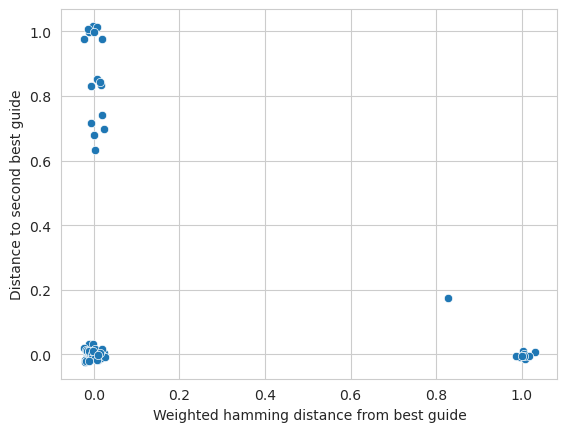

In [108]:
# add jitter
stab = tab.copy()
stab.guide_score = (stab.guide_score + np.random.normal(0, 0.0005, len(stab.guide_score)))*guide_length
stab.guide_certainty = (stab.guide_certainty + np.random.normal(0, 0.0005, len(stab.guide_certainty)))*guide_length

with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots()
sns.scatterplot(data=stab, x='guide_score', y='guide_certainty', ax=ax)
pl.xlabel('Weighted hamming distance from best guide')
pl.ylabel('Distance to second best guide')
pl.show()

## old

In [303]:
res = []
indices = []
df = pd.DataFrame(index=ids, columns='guide_id, guide_hit, guide_score, guide_certainty, next_best_guide, primer_idx, primer_hit, primer_score, primer_certainty'.split(', '))
for i in tqdm(range(20)):
    df.loc[ids[i]] = identify_guide(sequences[i], qual[i])

  0%|          | 0/20 [00:00<?, ?it/s]

AACAGACATTACTAATTTTGCCA  guide seq was likely not found in guide list!, quality >= 70


  5%|▌         | 1/20 [00:00<00:10,  1.78it/s]

AACAGACATTACTAATTTTGCCA  guide seq was likely not found in guide list!, quality >= 70


 10%|█         | 2/20 [00:01<00:10,  1.78it/s]

AGACATTACTAATTTTGCCAGTC  guide seq was likely not found in guide list!, quality >= 70


... (17 outputs left out)

AGACATTACTAATTTTGCCAGTC  guide seq was likely not found in guide list!, quality >= 70


 95%|█████████▌| 19/20 [00:10<00:00,  1.77it/s]

AGACATTACTAATTTTGCCAGTC  guide seq was likely not found in guide list!, quality >= 70


100%|██████████| 20/20 [00:11<00:00,  1.77it/s]


In [286]:
df.dropna()

,guide_id,guide_hit,guide_score,guide_certainty,next_best_guide,primer_idx,primer_hit,primer_score,primer_certainty
@A00510:908:HW3NNDRX3:1:2101:1994:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,HNRNPU_ENST00000440865_180,AGACATTACTAATTTTGCCAGTC,0.0,0.347826,DAP3_ENST00000368336_1668,33,ACCCCTTCCAAAAGTACGCCGTTTGAAAC,0.202162,0.378378
@A00510:908:HW3NNDRX3:1:2101:3676:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,HNRNPU_ENST00000440865_180,AGACATTACTAATTTTGCCAGTC,0.0,0.347826,DAP3_ENST00000368336_1668,33,ACCCCTACCAAAAGTACCCCGTTTGAAAC,0.232932,0.358434
@A00510:908:HW3NNDRX3:1:2101:3947:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,CTDP1_ENST00000299543_1020,AAAGAGATTTCTAAGGTTTCCCG,0.304348,0.0,PLRG1_ENST00000302078_812,31,ACCCCTACCAACTTGTCGGGCTTTGAAAC,0.065979,0.51134
@A00510:908:HW3NNDRX3:1:2101:6605:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,RCE1_ENST00000309657_714,GCAGCAGACAAGAAGATGTTCCC,0.434783,0.043478,FALEC_ENST00000416894_200,28,ACCCCTTCCTACTGGTCGGGGTTTGAAAC,0.071211,0.430315
@A00510:908:HW3NNDRX3:1:2101:8847:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,RCE1_ENST00000309657_714,GCAGCAGACAAGAAGATGTTCCC,0.434783,0.043478,FALEC_ENST00000416894_200,28,ACCCCTTCCTACTGGTCGGTGTAAGAAAC,0.149269,0.41858
@A00510:908:HW3NNDRX3:1:2101:8919:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,RCE1_ENST00000309657_714,GCAGCAGACAAGAAGATGTTCCC,0.434783,0.043478,FALEC_ENST00000416894_200,28,ACCCCTTCCTACTGGTCGGGCTTTCAAAC,0.120763,0.431144
@A00510:908:HW3NNDRX3:1:2101:10963:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,BBS2_ENST00000245157_1980,AACAGAAAGTTCTGACCGAGCCA,0.347826,0.0,RHEB_ENST00000472642_442,30,ACCCCTACCTACTGTACTCGCAATGAAAC,0.252289,0.427263
@A00510:908:HW3NNDRX3:1:2101:11650:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,HNRNPU_ENST00000440865_180,AGACATTACTAATTTTGCCAGTC,0.0,0.347826,DAP3_ENST00000368336_1668,33,ACCCCTTCCAAAAGTACGCCGTTTGAAAC,0.223577,0.355691
@A00510:908:HW3NNDRX3:1:2101:13259:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,HNRNPU_ENST00000440865_180,AGACATTACTAATTTTGCCAGTC,0.0,0.347826,DAP3_ENST00000368336_1668,33,AGCCCTACCAAATGGTCGGGGTTTGAAAC,0.053628,0.443743
@A00510:908:HW3NNDRX3:1:2101:13277:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,CTDP1_ENST00000299543_1020,AAAGAGATTTCTAAGGTTTCCCG,0.304348,0.0,PLRG1_ENST00000302078_812,31,ACCCCTACCAACTGGTCCGCCTTTGAAAC,0.103448,0.482759


In [234]:
df.dropna()

,guide_id,guide_hit,guide_score,guide_certainty,next_best_guide,primer_idx,primer_hit,primer_score,primer_certainty
@A00510:908:HW3NNDRX3:1:2101:1994:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,HNRNPU_ENST00000440865_180,AGACATTACTAATTTTGCCAGTC,0.0,0.347826,DAP3_ENST00000368336_1668,33,ACCCCTTCCAAAAGTACGCCGTTTGAAAC,0.202162,0.378378
@A00510:908:HW3NNDRX3:1:2101:3676:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,HNRNPU_ENST00000440865_180,AGACATTACTAATTTTGCCAGTC,0.0,0.347826,DAP3_ENST00000368336_1668,33,ACCCCTACCAAAAGTACCCCGTTTGAAAC,0.232932,0.358434
@A00510:908:HW3NNDRX3:1:2101:3947:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,CTDP1_ENST00000299543_1020,AAAGAGATTTCTAAGGTTTCCCG,0.304348,0.0,PLRG1_ENST00000302078_812,31,ACCCCTACCAACTTGTCGGGCTTTGAAAC,0.065979,0.51134
@A00510:908:HW3NNDRX3:1:2101:6605:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,RCE1_ENST00000309657_714,GCAGCAGACAAGAAGATGTTCCC,0.434783,0.043478,FALEC_ENST00000416894_200,28,ACCCCTTCCTACTGGTCGGGGTTTGAAAC,0.071211,0.430315
@A00510:908:HW3NNDRX3:1:2101:8847:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,RCE1_ENST00000309657_714,GCAGCAGACAAGAAGATGTTCCC,0.434783,0.043478,FALEC_ENST00000416894_200,28,ACCCCTTCCTACTGGTCGGTGTAAGAAAC,0.149269,0.41858
...,...,...,...,...,...,...,...,...,...
@A00510:908:HW3NNDRX3:1:2101:5439:1078 1:N:0:ATGTTGCCAC+TAGAAGCCAT,HNRNPU_ENST00000440865_180,AGACATTACTAATTTTGCCAGTC,0.0,0.347826,DAP3_ENST00000368336_1668,33,ACCCCTTCCAAAAGTACCCGGTTTGAAAC,0.218014,0.306039
@A00510:908:HW3NNDRX3:1:2101:5602:1078 1:N:0:ATGTTGCCAC+TAGAAGCCAT,RCE1_ENST00000309657_714,GCAGCAGACAAGAAGATGTTCCC,0.434783,0.043478,FALEC_ENST00000416894_200,28,ACCCCTACCTACTGGTCGGTCTAAGAAAC,0.135762,0.471302
@A00510:908:HW3NNDRX3:1:2101:5620:1078 1:N:0:ATGTTGCCAC+TAGAAGCCAT,RCE1_ENST00000309657_714,GCAGCAGACAAGAAGATGTTCCC,0.434783,0.043478,FALEC_ENST00000416894_200,28,ACCCCTACCAACTGGTCGGGCTATCAAAC,0.079434,0.522307
@A00510:908:HW3NNDRX3:1:2101:9218:1078 1:N:0:ATGTTGCCAC+TAGAAGCCAT,HNRNPU_ENST00000440865_180,AGACATTACTAATTTTGCCAGTC,0.0,0.347826,DAP3_ENST00000368336_1668,33,ACCCCTACCAAAAGTACCCCGTTTGAAAC,0.231537,0.349301
